In [11]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import torch.optim as optim

from flower_categories import flower_names
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from scipy.io import loadmat

In [2]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

dataset = datasets.Flowers102(
    root="./data",
    split="train",
    download=True,
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
)

100%|██████████| 345M/345M [00:37<00:00, 9.16MB/s] 
100%|██████████| 502/502 [00:00<00:00, 164kB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 3.71MB/s]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0322802..2.5179958].


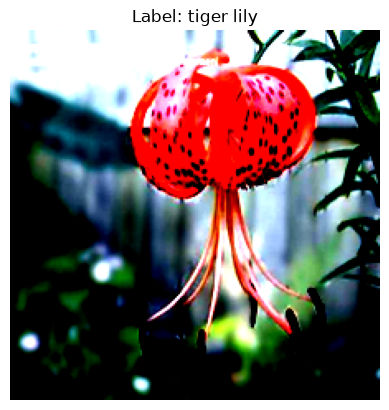

In [50]:
image, label = dataset[50]
image = image.permute(1,2,0)

plt.imshow(image)
plt.title(f"Label: {flower_names[label+1]}")
plt.axis("off")
plt.show()

In [ ]:
class DenseLayer(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super(DenseLayer, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.conv = nn.Conv2d(in_channels, growth_rate, kernel_size=3, stride=1, padding=1, bias=False)
        
    def forward(self, x):
        out = self.conv(F.relu(self.bn(x)))
        return torch.cat([x, out], dim=1)

class DenseBlock(nn.Module):
    def __init__(self, num_layers, in_channels, growth_rate):
        super(DenseBlock, self).__init__()
        self.layers = nn.ModuleList()
        current_channels = in_channels
        
        for _ in range(num_layers):
            self.layers.append(DenseLayer(current_channels, growth_rate))
            current_channels += growth_rate
            
    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

class TransitionLayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(TransitionLayer, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
    
    def forward(self, x):
        out = self.pool(self.conv(F.relu(self.bn(x))))
        return out

class FlowersDenseNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=102, growth_rate=32):
        super(FlowersDenseNet, self).__init__()
        
        # 1. Initial Stem (Outputs 64 channels)
        self.init_conv = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        
        # 2. Block 1: Input 64 -> Output 64 + (4 * 32) = 192 channels
        self.block1 = DenseBlock(num_layers=4, in_channels=64, growth_rate=growth_rate)        
        
        # 3. Transition 1: Input 192 -> Compressed to 96 channels
        self.trans1 = TransitionLayer(in_channels=192, out_channels=96)
        
        # 4. Block 2: Input 96 -> Output 96 + (4 * 32) = 224 channels
        self.block2 = DenseBlock(num_layers=4, in_channels=96, growth_rate=growth_rate)
        
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1)) 
        self.fc = nn.Linear(224, num_classes) # Matches block2 output channels
        
    def forward(self, x):
        x = self.init_conv(x)
        x = self.trans1(self.block1(x))
        x = self.block2(x)
        
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

In [14]:
model = FlowersDenseNet(in_channels=3, num_classes=102, growth_rate=32)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 5

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    
    for batch_idx, (images, labels) in enumerate(loader):
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct_predictions += (predicted == labels).sum().item()
        total_samples += labels.size(0)
        
        if (batch_idx + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Batch [{batch_idx+1}/{len(loader)}], Loss: {loss.item():.4f}")

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions / total_samples
    print(f"==> Epoch {epoch+1} Complete | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc * 100:.2f}%\n")

print("Training finished!")

NotImplementedError: Module [DenseBlock] is missing the required "forward" function

In [15]:
class DenseLayer(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super(DenseLayer, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.conv = nn.Conv2d(in_channels, growth_rate, kernel_size=3, stride=1, padding=1, bias=False)
        
    def forward(self, x):
        out = self.conv(F.relu(self.bn(x)))
        return torch.cat([x, out], dim=1)

class DenseBlock(nn.Module):
    def __init__(self, num_layers, in_channels, growth_rate):
        super(DenseBlock, self).__init__()
        self.layers = nn.ModuleList()
        current_channels = in_channels
        
        for _ in range(num_layers):
            self.layers.append(DenseLayer(current_channels, growth_rate))
            current_channels += growth_rate
            
    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

class TransitionLayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(TransitionLayer, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
    
    def forward(self, x):
        out = self.pool(self.conv(F.relu(self.bn(x))))
        return out

class FlowersDenseNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=102, growth_rate=32):
        super(FlowersDenseNet, self).__init__()
        
        # 1. Initial Stem (Outputs 64 channels)
        self.init_conv = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        
        # 2. Block 1: Input 64 -> Output 64 + (4 * 32) = 192 channels
        self.block1 = DenseBlock(num_layers=4, in_channels=64, growth_rate=growth_rate)        
        
        # 3. Transition 1: Input 192 -> Compressed to 96 channels
        self.trans1 = TransitionLayer(in_channels=192, out_channels=96)
        
        # 4. Block 2: Input 96 -> Output 96 + (4 * 32) = 224 channels
        self.block2 = DenseBlock(num_layers=4, in_channels=96, growth_rate=growth_rate)
        
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1)) 
        self.fc = nn.Linear(224, num_classes)
        
    def forward(self, x):
        x = self.init_conv(x)
        x = self.trans1(self.block1(x))
        x = self.block2(x)
        
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

# Instantiate model (runs on CPU)
model = FlowersDenseNet(in_channels=3, num_classes=102, growth_rate=32)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 5

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    
    for batch_idx, (images, labels) in enumerate(loader):
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct_predictions += (predicted == labels).sum().item()
        total_samples += labels.size(0)
        
        if (batch_idx + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Batch [{batch_idx+1}/{len(loader)}], Loss: {loss.item():.4f}")

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions / total_samples
    print(f"==> Epoch {epoch+1} Complete | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc * 100:.2f}%\n")

print("Training finished!")

Epoch [1/5], Batch [10/32], Loss: 5.3012
Epoch [1/5], Batch [20/32], Loss: 5.2229
Epoch [1/5], Batch [30/32], Loss: 5.0500
==> Epoch 1 Complete | Loss: 5.1544 | Accuracy: 0.00%

Epoch [2/5], Batch [10/32], Loss: 5.1964
Epoch [2/5], Batch [20/32], Loss: 4.8357
Epoch [2/5], Batch [30/32], Loss: 5.4170
==> Epoch 2 Complete | Loss: 5.3391 | Accuracy: 0.00%

Epoch [3/5], Batch [10/32], Loss: 4.6325
Epoch [3/5], Batch [20/32], Loss: 4.3829
Epoch [3/5], Batch [30/32], Loss: 4.9871
==> Epoch 3 Complete | Loss: 4.6263 | Accuracy: 0.00%

Epoch [4/5], Batch [10/32], Loss: 4.5599
Epoch [4/5], Batch [20/32], Loss: 4.2846
Epoch [4/5], Batch [30/32], Loss: 4.7211
==> Epoch 4 Complete | Loss: 4.4956 | Accuracy: 0.29%

Epoch [5/5], Batch [10/32], Loss: 4.4677
Epoch [5/5], Batch [20/32], Loss: 4.1005
Epoch [5/5], Batch [30/32], Loss: 4.6399
==> Epoch 5 Complete | Loss: 4.3173 | Accuracy: 1.27%

Training finished!


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

# 1. Transforms with required ImageNet normalization
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

# 2. Load Flowers102 Dataset
dataset = datasets.Flowers102(
    root="./data",
    split="train",
    download=True,
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True,
)

# 3. Load Pre-trained DenseNet121
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)

# 4. Freeze feature extraction parameters (so we only train the new classifier head)
for param in model.parameters():
    param.requires_grad = False

# 5. Replace the final classification layer for 102 flower categories
num_ftrs = model.classifier.in_features
model.classifier = nn.Linear(num_ftrs, 102)

# 6. Loss and Optimizer (only optimizing the new classifier layer)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

# 7. Training Loop (runs on CPU)
num_epochs = 5
model.train()

for epoch in range(num_epochs):
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    
    for batch_idx, (images, labels) in enumerate(loader):
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct_predictions += (predicted == labels).sum().item()
        total_samples += labels.size(0)
        
        if (batch_idx + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Batch [{batch_idx+1}/{len(loader)}], Loss: {loss.item():.4f}")

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions / total_samples
    print(f"==> Epoch {epoch+1} Complete | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc * 100:.2f}%\n")


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\PERSONAL/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:02<00:00, 10.8MB/s]


Epoch [1/5], Batch [10/32], Loss: 5.2009
Epoch [1/5], Batch [20/32], Loss: 4.7243
Epoch [1/5], Batch [30/32], Loss: 4.2126
==> Epoch 1 Complete | Loss: 4.6135 | Accuracy: 6.37%

Epoch [2/5], Batch [10/32], Loss: 3.5064
Epoch [2/5], Batch [20/32], Loss: 2.9804
Epoch [2/5], Batch [30/32], Loss: 2.8544
==> Epoch 2 Complete | Loss: 3.1925 | Accuracy: 50.29%

Epoch [3/5], Batch [10/32], Loss: 2.3861
Epoch [3/5], Batch [20/32], Loss: 2.4401
Epoch [3/5], Batch [30/32], Loss: 1.6629
==> Epoch 3 Complete | Loss: 2.2006 | Accuracy: 81.57%

Epoch [4/5], Batch [10/32], Loss: 1.5918
Epoch [4/5], Batch [20/32], Loss: 1.5937
Epoch [4/5], Batch [30/32], Loss: 1.1653
==> Epoch 4 Complete | Loss: 1.4937 | Accuracy: 92.35%

Epoch [5/5], Batch [10/32], Loss: 1.0483
Epoch [5/5], Batch [20/32], Loss: 0.8186
Epoch [5/5], Batch [30/32], Loss: 1.0231
==> Epoch 5 Complete | Loss: 1.0319 | Accuracy: 97.65%

Transfer learning training finished!


In [51]:
from PIL import Image

model.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    # Keep this normalization line only if you used it during training
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Load your local flower image
image_path = "../data/tiger lily.jpg"  # Replace with your image file path
image = Image.open(image_path).convert("RGB")

# 4. Preprocess and add a batch dimension [1, 3, 224, 224]
input_tensor = transform(image).unsqueeze(0)

# 5. Run inference (no_grad() speeds up computation and saves memory)
with torch.no_grad():
    outputs = model(input_tensor)
    
    # Convert raw logits to confidence probabilities
    probabilities = torch.softmax(outputs, dim=1)
    
    # Get the highest scoring class index and its confidence score
    confidence, predicted_idx = torch.max(probabilities, dim=1)

print(f"Predicted Class Index: {flower_names[predicted_idx.item()+1]}")
print(f"Confidence Score: {confidence.item() * 100:.2f}%")

Predicted Class Index: tiger lily
Confidence Score: 71.25%
